# Análisis y Modelado de Series de Tiempo con ARIMA

Este notebook recorre el flujo de trabajo completo para analizar y modelar una serie de tiempo con **ARIMA**:

1. Visualización exploratoria
2. Prueba de estacionariedad (ADF)
3. Descomposición de la serie (tendencia, estacionalidad, residuo)
4. Autocorrelación (ACF) y autocorrelación parcial (PACF)
5. Selección de los parámetros **p, d, q**:
   - Manual, interpretando ACF/PACF y comparando AIC/BIC
   - Automática, con `pmdarima.auto_arima`
6. Entrenamiento del modelo y evaluación
7. Forecasting (pronóstico) sobre datos de prueba y a futuro

Como serie de ejemplo se usa el dataset de **CO2 atmosférico mensual (Mauna Loa)**, incluido en `statsmodels`, porque no requiere descargar nada externo y tiene tendencia y estacionalidad claras — ideal para explicar cada paso. Puedes reemplazar la carga de datos por tu propia serie sin cambiar el resto del notebook, siempre que termines con una `pandas.Series` con índice de fechas (`DatetimeIndex`) y frecuencia definida.

In [1]:
pip install pmdarima

   ---------------------------------------- 0.0/711.9 kB ? eta -:--:--
   -------------- ------------------------- 262.1/711.9 kB ? eta -:--:--
   ---------------------------------------- 711.9/711.9 kB 3.5 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 2.9/2.9 MB 14.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/818.2 kB ? eta -:--:--
   --------------------------------------- 818.2/818.2 kB 18.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import warnings

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error

import pmdarima as pm

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 0. Datos

Cargamos la serie de CO2 mensual, interpolamos los pocos valores faltantes y fijamos la frecuencia mensual (`MS` = inicio de mes), algo indispensable para que `statsmodels` reconozca correctamente la estacionalidad.

In [2]:
datos = sm.datasets.co2.load_pandas().data
co2 = datos["co2"]
co2 = co2.resample("MS").mean()       # aseguramos frecuencia mensual regular
co2 = co2.interpolate()               # rellenamos huecos pequeños
co2.name = "co2_ppm"
co2.index.name = "fecha"

print(f"Rango de fechas: {co2.index.min().date()} -> {co2.index.max().date()}")
print(f"Número de observaciones: {len(co2)}")
co2.head()

Rango de fechas: 1958-03-01 -> 2001-12-01
Número de observaciones: 526


fecha
1958-03-01    316.100000
1958-04-01    317.200000
1958-05-01    317.433333
1958-06-01    316.529167
1958-07-01    315.625000
Freq: MS, Name: co2_ppm, dtype: float64

## 1. Visualización

Antes de cualquier prueba estadística, siempre conviene *mirar* la serie: ¿hay tendencia?, ¿hay estacionalidad?, ¿la varianza cambia con el tiempo? Aquí graficamos la serie junto con su media y desviación estándar móviles (ventana de 12 meses), que son una forma visual rápida de detectar no estacionariedad.

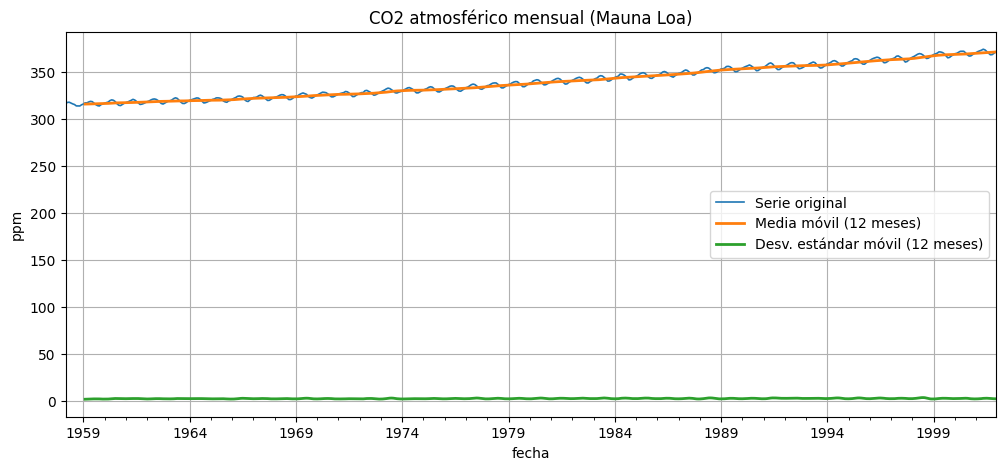

In [3]:
fig, ax = plt.subplots()
co2.plot(ax=ax, label="Serie original", linewidth=1.2)
co2.rolling(12).mean().plot(ax=ax, label="Media móvil (12 meses)", linewidth=2)
co2.rolling(12).std().plot(ax=ax, label="Desv. estándar móvil (12 meses)", linewidth=2)
ax.set_title("CO2 atmosférico mensual (Mauna Loa)")
ax.set_ylabel("ppm")
ax.legend()
plt.show()

**Lectura:** la media móvil sube de forma sostenida (tendencia) y la serie muestra un patrón que se repite cada 12 meses (estacionalidad anual). La desviación estándar móvil es relativamente estable, así que no parece necesaria una transformación de varianza (log, Box-Cox).

## 2. Prueba de estacionariedad: ADF

Un modelo ARIMA necesita una serie **estacionaria** (media y varianza constantes en el tiempo) en la parte no estacional. Usamos la prueba **ADF (Augmented Dickey-Fuller)**, vista en clase:

- H0: la serie **tiene raíz unitaria** (no es estacionaria).
- H1: la serie **no tiene raíz unitaria** (es estacionaria).

Si el p-valor es menor que el nivel de significancia (0.05), rechazamos H0 y concluimos que la serie es estacionaria.

In [4]:
def prueba_adf(serie, nombre=""):
    resultado = adfuller(serie.dropna(), autolag="AIC")
    print(f"--- ADF: {nombre} ---")
    print(f"Estadístico: {resultado[0]:.4f} | p-valor: {resultado[1]:.4f}")
    for clave, valor in resultado[4].items():
        print(f"  Valor crítico {clave}: {valor:.4f}")
    es_estacionaria = resultado[1] < 0.05
    print(f"Conclusión (alfa=0.05): {'Estacionaria' if es_estacionaria else 'No estacionaria'}\n")
    return es_estacionaria

_ = prueba_adf(co2, "serie original")

--- ADF: serie original ---
Estadístico: 2.2328 | p-valor: 0.9989
  Valor crítico 1%: -3.4432
  Valor crítico 5%: -2.8672
  Valor crítico 10%: -2.5698
Conclusión (alfa=0.05): No estacionaria



La prueba ADF indica que la serie **no es estacionaria**. Diferenciamos una vez (`d=1`) y repetimos la prueba.

--- ADF: primera diferencia (d=1) ---
Estadístico: -4.7519 | p-valor: 0.0001
  Valor crítico 1%: -3.4432
  Valor crítico 5%: -2.8672
  Valor crítico 10%: -2.5698
Conclusión (alfa=0.05): Estacionaria



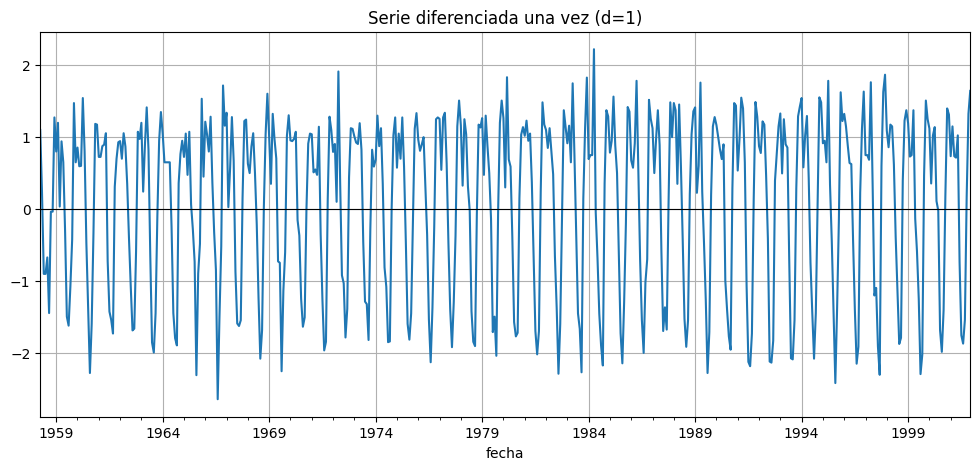

In [5]:
co2_diff1 = co2.diff().dropna()

_ = prueba_adf(co2_diff1, "primera diferencia (d=1)")

fig, ax = plt.subplots()
co2_diff1.plot(ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Serie diferenciada una vez (d=1)")
plt.show()

Con una diferencia, la prueba ADF concluye que la serie **es estacionaria**, así que fijamos `d = 1` para la parte no estacional. También podemos confirmarlo de forma automática con la función `ndiffs` de `pmdarima`, que aplica la prueba ADF repetidamente hasta encontrar el número mínimo de diferencias necesarias.

In [6]:
from pmdarima.arima import ndiffs

d_adf = ndiffs(co2, test="adf")
print(f"Diferencias sugeridas por ADF: {d_adf}")

Diferencias sugeridas por ADF: 1


## 3. Descomposición de la serie

Descomponer la serie en **tendencia + estacionalidad + residuo** con `seasonal_decompose` ayuda a confirmar visualmente lo que ya sugerían las pruebas anteriores, y a decidir si haría falta un componente estacional (SARIMA) en vez de un ARIMA simple.

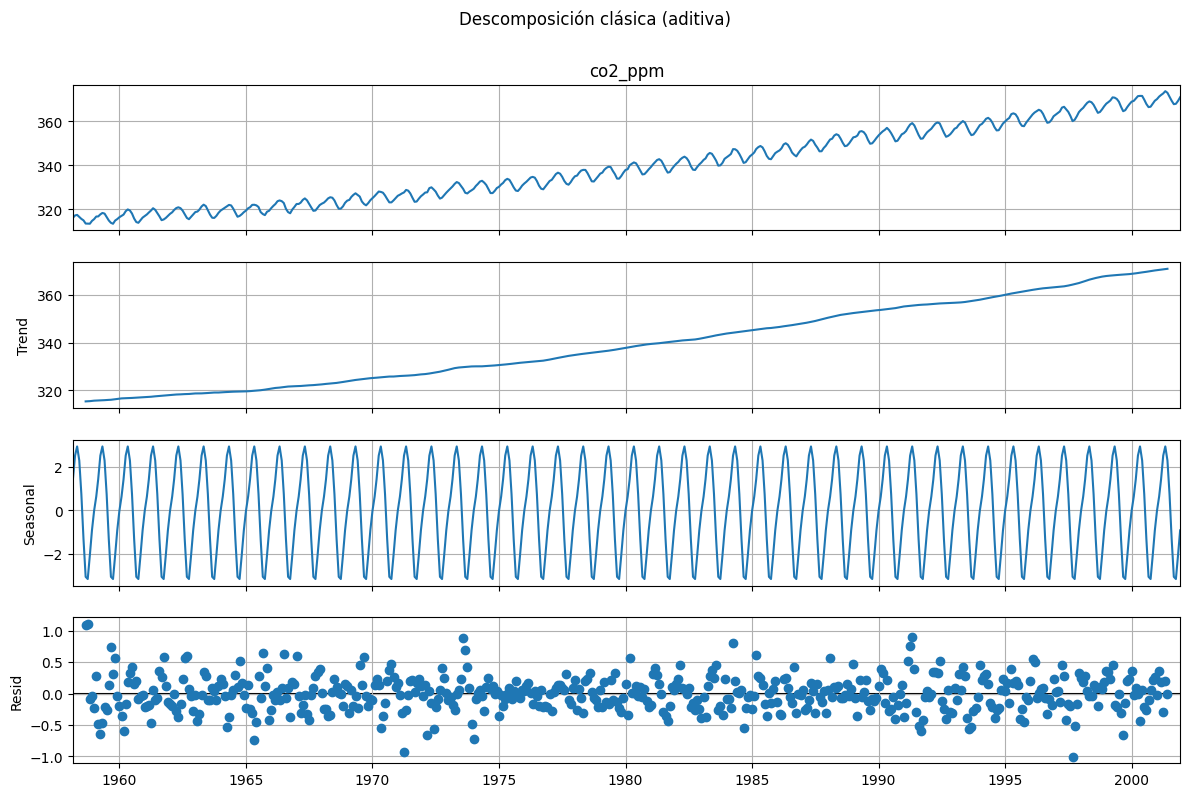

In [12]:
descomposicion = seasonal_decompose(co2, model="additive", period=12)
fig = descomposicion.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Descomposición clásica (aditiva)", y=1.02)
plt.show()

**Lectura:** el residuo de la descomposición todavía muestra algo de estructura (no es puro ruido blanco), y el componente estacional es notorio. Esto es una señal de que, en un proyecto real, probablemente convendría un **SARIMA** (con componente estacional) en vez de un ARIMA simple. Seguimos con ARIMA para efectos didácticos, pero se menciona la alternativa al final.

## 4. Autocorrelación (ACF) y autocorrelación parcial (PACF)

Sobre la serie ya estacionaria (`co2_diff1`) miramos:

- **ACF**: ayuda a identificar el orden `q` (parte de medias móviles / MA). Se busca el último rezago donde la autocorrelación es significativa antes de "cortar" o decaer.
- **PACF**: ayuda a identificar el orden `p` (parte autorregresiva / AR). Igual, se busca dónde "corta".

La banda azul sombreada es el intervalo de confianza (por defecto 95%): rezagos dentro de la banda se consideran no significativos.

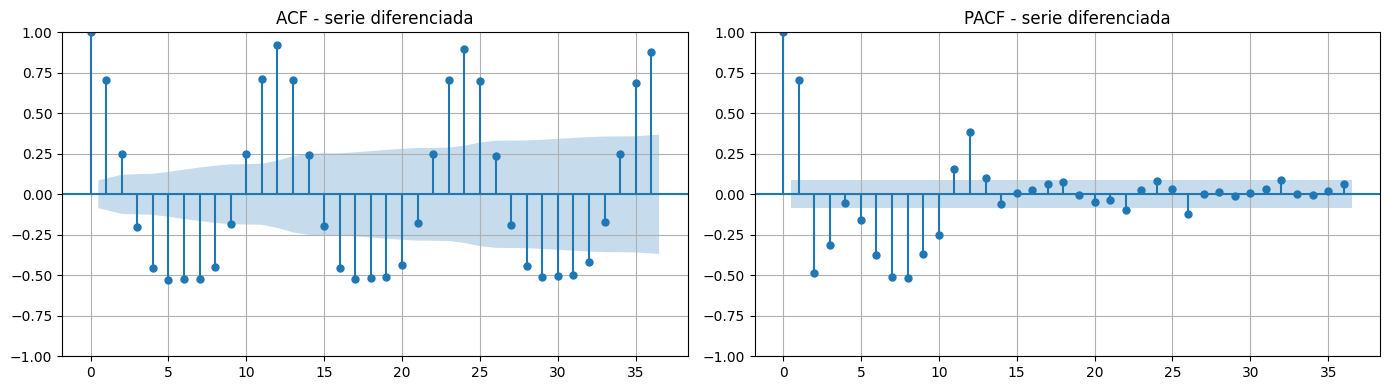

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(co2_diff1, lags=36, ax=ejes[0])
ejes[0].set_title("ACF - serie diferenciada")
plot_pacf(co2_diff1, lags=36, ax=ejes[1], method="ywm")
ejes[1].set_title("PACF - serie diferenciada")
plt.tight_layout()
plt.show()

**Lectura:**

- La PACF corta abruptamente después de 1-2 rezagos → sugiere `p` pequeño (1 o 2).
- La ACF decae más lentamente y muestra picos periódicos cerca del rezago 12 → confirma la estacionalidad anual que ya vimos en la descomposición (indicio adicional de que un componente estacional ayudaría).

Con esto tenemos un punto de partida razonable: `d = 1`, `p` entre 0 y 2, `q` entre 0 y 2. En la siguiente sección afinamos esa elección de dos maneras: revisando combinaciones manualmente y de forma automática.

## 5. Selección de los parámetros (p, d, q)

### 5.1 Revisión manual (grid search + AIC/BIC)

Partiendo de lo leído en ACF/PACF, probamos varias combinaciones de `(p, d, q)` alrededor de esos valores y comparamos criterios de información (**AIC**, **BIC**): valores más bajos indican mejor equilibrio entre ajuste y complejidad del modelo.

In [14]:
def comparar_ordenes(serie, rango_p, rango_d, rango_q):
    resultados = []
    for p, d, q in itertools.product(rango_p, rango_d, rango_q):
        try:
            modelo = ARIMA(serie, order=(p, d, q)).fit()
            resultados.append({"p": p, "d": d, "q": q, "AIC": modelo.aic, "BIC": modelo.bic})
        except Exception:
            continue
    return pd.DataFrame(resultados).sort_values("AIC").reset_index(drop=True)

tabla_ordenes = comparar_ordenes(co2, rango_p=range(0, 4), rango_d=[1], rango_q=range(0, 4))
tabla_ordenes.head(100)

,p,d,q,AIC,BIC
0,2,1,1,1048.325945,1065.379538
1,3,1,3,1048.397426,1078.241214
2,2,1,2,1050.106207,1071.423199
3,3,1,1,1050.123523,1071.440514
4,3,1,2,1050.993514,1076.573904
5,2,1,3,1053.236428,1078.816818
6,3,1,0,1120.992100,1138.045693
7,0,1,3,1169.150226,1186.203819
8,1,1,3,1170.140108,1191.457100
9,2,1,0,1173.329867,1186.120061


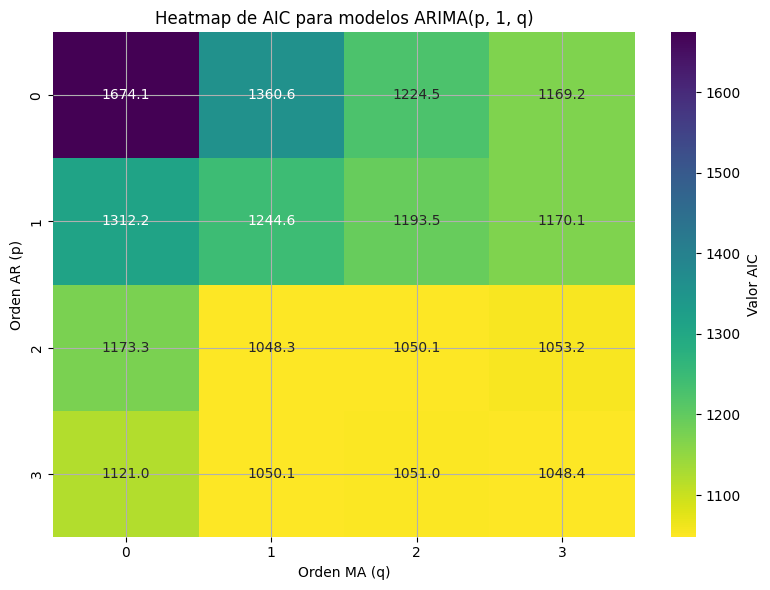

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Crear una tabla pivotante (matriz) donde 'p' son las filas, 'q' las columnas y los valores son el 'AIC'
pivot_aic = tabla_ordenes.pivot(index='p', columns='q', values='AIC')

# 2. Configurar el tamaño de la figura
plt.figure(figsize=(8, 6))

# 3. Generar el mapa de calor
# annot=True muestra los números dentro de las celdas
# cmap="viridis_r" usa una paleta de colores donde los colores más claros (o amarillos) representan los valores más bajos (mejores AIC)
sns.heatmap(pivot_aic, annot=True, fmt=".1f", cmap="viridis_r", cbar_kws={'label': 'Valor AIC'})

# 4. Añadir etiquetas para mayor claridad
plt.title("Heatmap de AIC para modelos ARIMA(p, 1, q)")
plt.xlabel("Orden MA (q)")
plt.ylabel("Orden AR (p)")

# Mostrar la gráfica
plt.tight_layout()
plt.show()

### 5.2 Selección automática (`pmdarima.auto_arima`)

`auto_arima` hace básicamente lo mismo que la celda anterior pero de forma más eficiente (búsqueda tipo *stepwise* en vez de probar todas las combinaciones) y decide `d` automáticamente con las mismas pruebas de estacionariedad que usamos arriba.

In [17]:
modelo_auto = pm.auto_arima(
    co2,
    start_p=0, start_q=0,
    max_p=5, max_q=5,
    d=None,              # lo decide auto_arima
    test="adf",          # usamos la misma prueba ADF vista en clase
    seasonal=False,      # ARIMA simple, sin componente estacional
    trace=True,          # muestra el proceso de búsqueda
    stepwise=True,
    suppress_warnings=True,
)

orden_auto = modelo_auto.order
print("\nOrden (p, d, q) sugerido automáticamente:", orden_auto)
print(modelo_auto.summary())

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1672.055, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1313.309, Time=0.06 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1359.730, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1674.131, Time=0.02 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=1173.169, Time=0.07 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=1118.917, Time=0.09 sec
 ARIMA(4,1,0)(0,0,0)[0] intercept   : AIC=1119.269, Time=0.10 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=983.424, Time=0.47 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=982.762, Time=0.22 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=1245.529, Time=0.07 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=983.017, Time=0.35 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1194.397, Time=0.10 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=984.759, Time=0.55 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=1048.326, Time=0.07 sec

Best model:  ARIMA(2,1,1)(0,0,0)[0] 

### 5.3 Orden final

Comparamos el mejor resultado de la búsqueda manual con el de `auto_arima`. En general, si ambos coinciden o son muy cercanos, es una buena señal. Aquí nos quedamos con el orden sugerido por `auto_arima` (`orden_auto`), pero queda explícito cómo compararlo con el mejor de la tabla manual.

In [19]:
mejor_manual = tuple(tabla_ordenes.iloc[0][["p", "d", "q"]].astype(int))
print(f"Mejor orden según búsqueda manual (AIC): {mejor_manual}")
print(f"Orden sugerido por auto_arima:            {orden_auto}")

orden_final = orden_auto
print(f"\nOrden final elegido para entrenar: {orden_final}")

Mejor orden según búsqueda manual (AIC): (2, 1, 1)
Orden sugerido por auto_arima:            (2, 1, 1)

Orden final elegido para entrenar: (2, 1, 1)


## 6. Entrenamiento y forecasting

### 6.1 División entrenamiento / prueba

Como es una serie de tiempo, la división **no debe ser aleatoria**: se reserva el tramo final (más reciente) como conjunto de prueba, para simular un escenario real de pronóstico a futuro.

In [20]:
n_prueba = 24  # últimos 24 meses como prueba
entrenamiento = co2.iloc[:-n_prueba]
prueba = co2.iloc[-n_prueba:]

print(f"Entrenamiento: {entrenamiento.index.min().date()} -> {entrenamiento.index.max().date()} ({len(entrenamiento)} obs.)")
print(f"Prueba:        {prueba.index.min().date()} -> {prueba.index.max().date()} ({len(prueba)} obs.)")

Entrenamiento: 1958-03-01 -> 1999-12-01 (502 obs.)
Prueba:        2000-01-01 -> 2001-12-01 (24 obs.)


### 6.2 Entrenamiento del modelo

In [21]:
modelo_final = ARIMA(entrenamiento, order=orden_final).fit()
print(modelo_final.summary())

                               SARIMAX Results                                
Dep. Variable:                co2_ppm   No. Observations:                  502
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -497.678
Date:                Sat, 17 Oct 2026   AIC                           1003.357
Time:                        11:37:01   BIC                           1020.223
Sample:                    03-01-1958   HQIC                          1009.975
                         - 12-01-1999                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5407      0.029     53.800      0.000       1.485       1.597
ar.L2         -0.8347      0.032    -25.735      0.000      -0.898      -0.771
ma.L1         -0.8078      0.038    -21.054      0.0

### 6.3 Diagnóstico de residuos

Antes de confiar en el modelo, revisamos que los residuos se comporten como ruido blanco: sin patrones, aproximadamente normales y sin autocorrelación significativa (prueba de Ljung-Box, incluida en el panel inferior derecho).

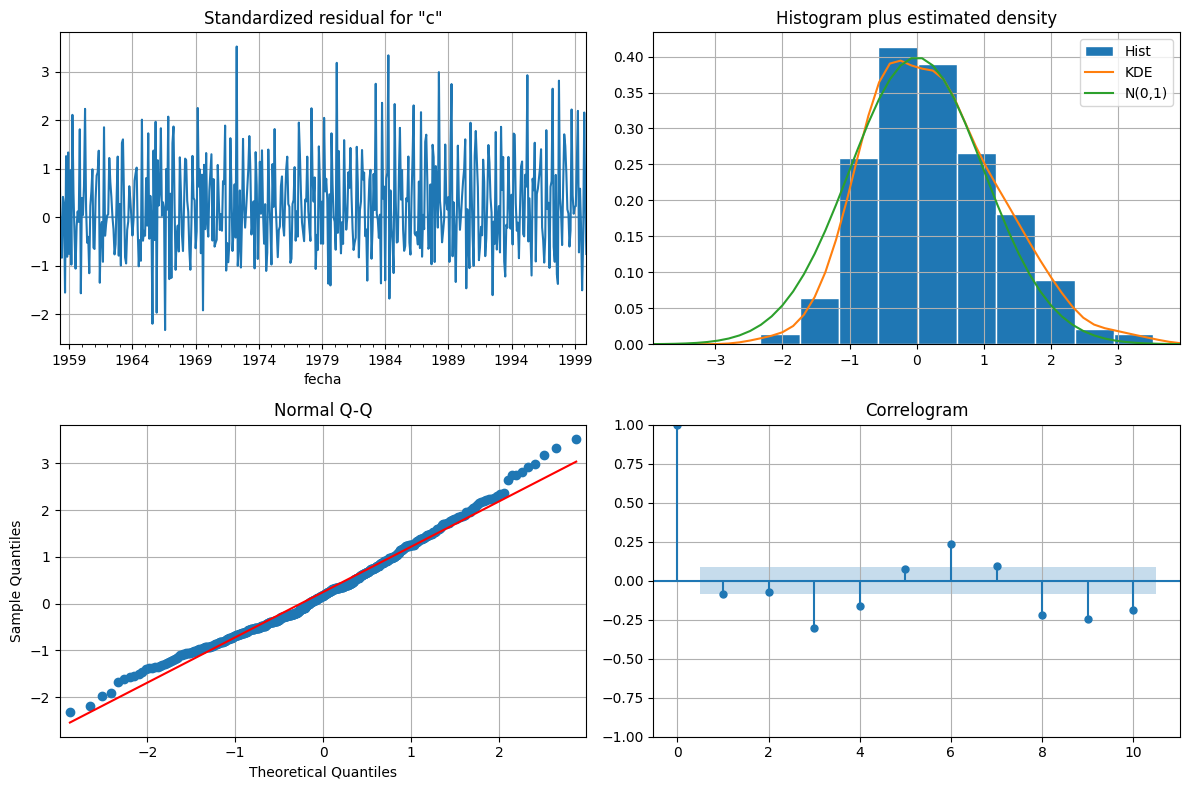

In [22]:
modelo_final.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

### 6.4 Forecasting sobre el conjunto de prueba y evaluación

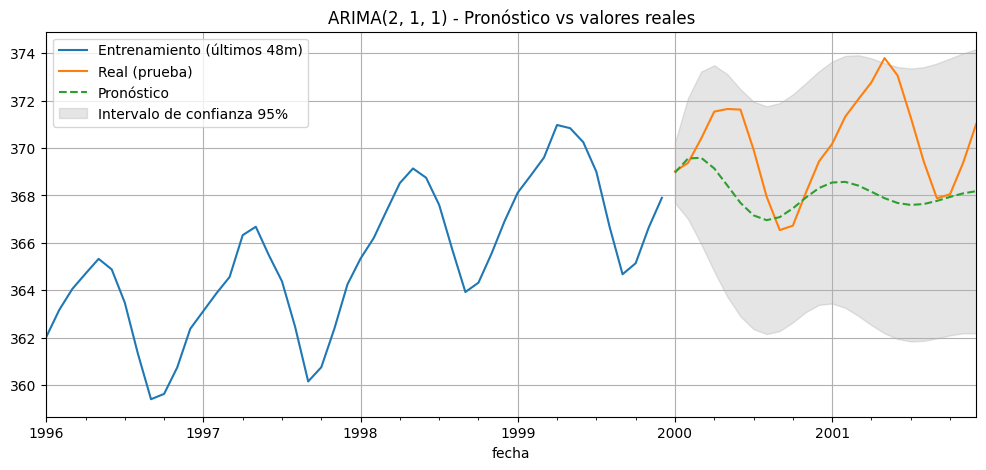

MAE:  2.1151
RMSE: 2.7277
MAPE: 0.57%


In [24]:
pronostico = modelo_final.get_forecast(steps=n_prueba)
media_pronostico = pronostico.predicted_mean
intervalo_confianza = pronostico.conf_int()

fig, ax = plt.subplots()
entrenamiento.iloc[-48:].plot(ax=ax, label="Entrenamiento (últimos 48m)")
prueba.plot(ax=ax, label="Real (prueba)")
media_pronostico.plot(ax=ax, label="Pronóstico", style="--")
ax.fill_between(
    intervalo_confianza.index,
    intervalo_confianza.iloc[:, 0],
    intervalo_confianza.iloc[:, 1],
    color="gray", alpha=0.2, label="Intervalo de confianza 95%",
)
ax.set_title(f"ARIMA{orden_final} - Pronóstico vs valores reales")
ax.legend()
plt.show()

mae = mean_absolute_error(prueba, media_pronostico)
rmse = np.sqrt(mean_squared_error(prueba, media_pronostico))
mape = np.mean(np.abs((prueba - media_pronostico) / prueba)) * 100

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")

### 6.5 Pronóstico a futuro (fuera de muestra)

Una vez validado el modelo con el conjunto de prueba, se reentrena con **toda** la serie disponible (entrenamiento + prueba) y se proyecta hacia adelante.

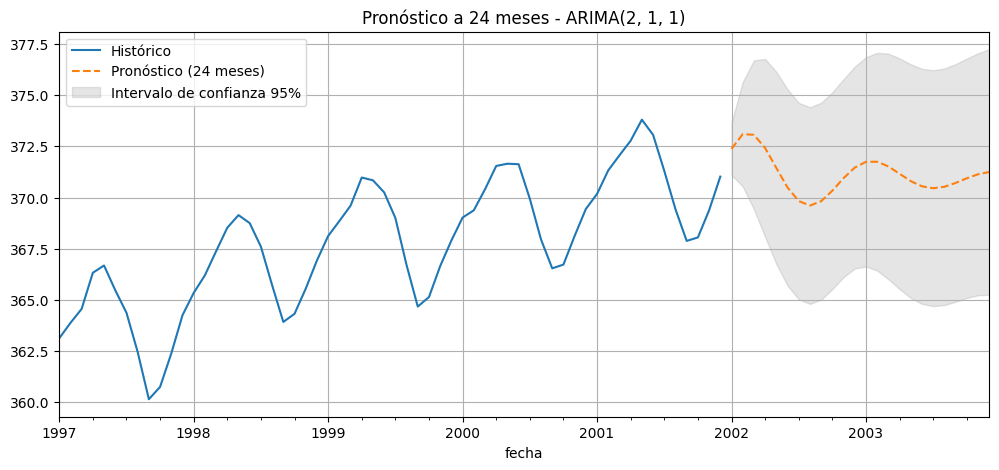

,pronostico,lower co2_ppm,upper co2_ppm
2002-01-01,372.376820,371.102259,373.651382
2002-02-01,373.092764,370.540616,375.644912
2002-03-01,373.061743,369.426356,376.697130
2002-04-01,372.415172,368.065527,376.764817
2002-05-01,371.444365,366.751124,376.137605


In [25]:
pasos_futuro = 24  # meses a pronosticar hacia adelante

modelo_produccion = ARIMA(co2, order=orden_final).fit()
pronostico_futuro = modelo_produccion.get_forecast(steps=pasos_futuro)
media_futuro = pronostico_futuro.predicted_mean
ic_futuro = pronostico_futuro.conf_int()

fig, ax = plt.subplots()
co2.iloc[-60:].plot(ax=ax, label="Histórico")
media_futuro.plot(ax=ax, label=f"Pronóstico ({pasos_futuro} meses)", style="--")
ax.fill_between(
    ic_futuro.index, ic_futuro.iloc[:, 0], ic_futuro.iloc[:, 1],
    color="gray", alpha=0.2, label="Intervalo de confianza 95%",
)
ax.set_title(f"Pronóstico a {pasos_futuro} meses - ARIMA{orden_final}")
ax.legend()
plt.show()

media_futuro.to_frame(name="pronostico").join(ic_futuro).head()